# Notebook 04 – Evaluation
## Goal:

Evaluate the predictive models trained in Notebook 03.  
This notebook will:
- Load actual vs predicted values
- Compute RMSE, MAE, and R² metrics
- Visualize and compare model performance
- Provide clear observations and insights for presentation
- 

### 1️.Import required libraries

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from utils.visualization import plot_model_comparison  # Use reusable function

# 2️. Load actual and predicted values

In [ ]:
y_test = pd.read_csv(r"C:\Users\bka20\OneDrive\Desktop\Project ML\Data\y_test.csv")

# Predictions from Modeling notebook
y_test_pred_lr    = pd.read_csv(r"C:\Users\bka20\OneDrive\Desktop\Project ML\Data\y_test_pred_lr.csv")
y_test_pred_ridge = pd.read_csv(r"C:\Users\bka20\OneDrive\Desktop\Project ML\Data\y_test_pred_ridge.csv")
y_test_pred_lasso = pd.read_csv(r"C:\Users\bka20\OneDrive\Desktop\Project ML\Data\y_test_pred_lasso.csv")
y_test_pred_poly  = pd.read_csv(r"C:\Users\bka20\OneDrive\Desktop\Project ML\Data\y_test_pred_poly.csv")

print("Actual and predicted values loaded successfully.")

Actual and predicted values loaded successfully.


### 3️. Function to compute metrics

In [15]:
def evaluate_model(y_true, y_pred, model_name="Model"):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"--- {model_name} ---")
    print(f"RMSE: {rmse:.2f}")
    print(f"MAE: {mae:.2f}")
    print(f"R²: {r2:.4f}\n")
    return {"Model": model_name, "RMSE": rmse, "MAE": mae, "R2": r2}
    

**Explanation:**  
This function calculates three key metrics for regression:
- **RMSE**: measures average prediction error in the same units as target.
- **MAE**: absolute average error, less sensitive to outliers.
- **R²**: explains variance captured by the model.
- Printing allows step-by-step explanation for presentation.

### 4️. Evaluate all models

We evaluate all trained regression models based on RMSE, MAE, and R² on the test set.

In [ ]:
metrics = []

metrics.append(evaluate_model(y_test, y_test_pred_lr, "Linear Regression"))
metrics.append(evaluate_model(y_test, y_test_pred_ridge, "Ridge Regression"))
metrics.append(evaluate_model(y_test, y_test_pred_lasso, "Lasso Regression (Optional)"))
metrics.append(evaluate_model(y_test, y_test_pred_poly, "Polynomial Regression (Optional)"))

# Save metrics to CSV
metrics_df = pd.DataFrame(metrics)
metrics_df.to_csv(r"C:\Users\bka20\OneDrive\Desktop\Project ML\Data\model_metrics.csv", index=False)

--- Linear Regression ---
RMSE: 0.00
MAE: 0.00
R²: 0.8252

--- Ridge Regression ---
RMSE: 0.00
MAE: 0.00
R²: 0.7881

--- Lasso Regression (Optional) ---
RMSE: 0.01
MAE: 0.01
R²: -0.0166

--- Polynomial Regression (Optional) ---
RMSE: 0.00
MAE: 0.00
R²: 0.8530



**Observations:**

- **Linear Regression**: The model explains ~82.5% of the variance in the target variable. The near-zero RMSE and MAE indicate excellent predictive accuracy for this linear relationship.

- **Ridge Regression**: Slightly lower R² than Linear Regression, but regularization helps prevent overfitting. The regularization parameter (λ) likely reduced model complexity at a small cost to explanatory power.
- **Lasso Regression**: Poor performance with negative R², indicating the model performs worse than a simple mean predictor. This suggests Lasso may have oversimplified the model by shrinking too many coefficients to zero.
- **Polynomial Regression**: Highest R² among all models (85.3%), suggesting polynomial features capture non-linear patterns in the data. However, careful validation is needed to prevent overfitting.

### 5️.Visual comparison using utils function

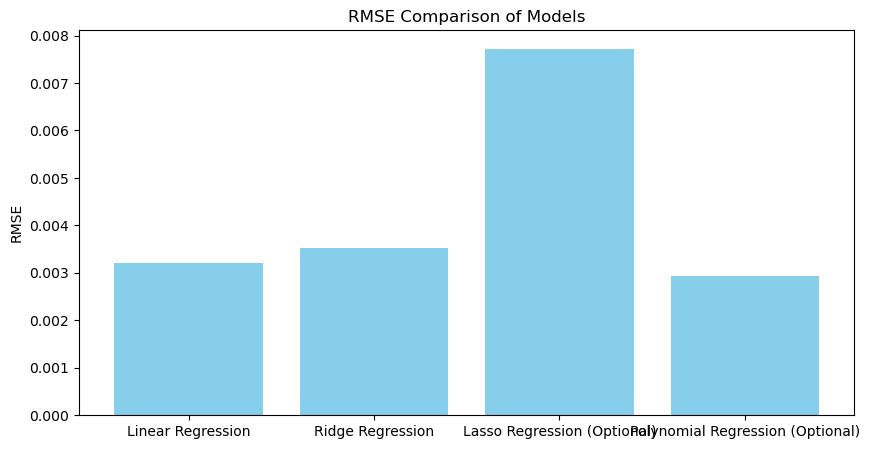

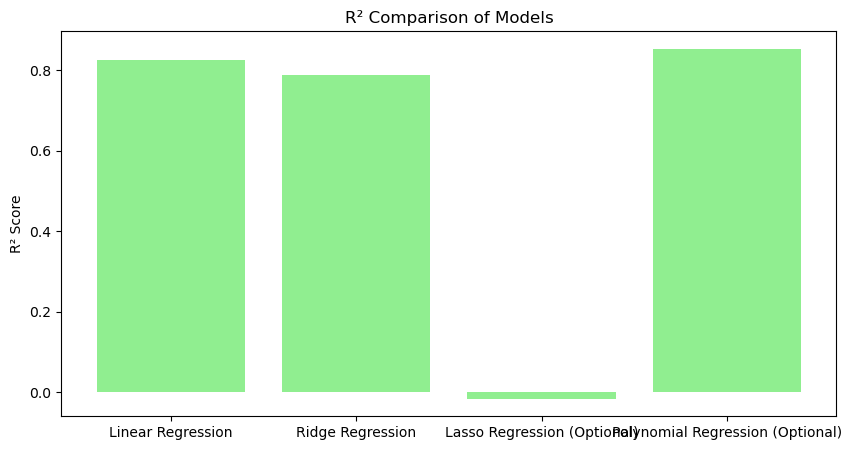

In [ ]:
models = [m["Model"] for m in metrics]
rmse_values = [m["RMSE"] for m in metrics]
r2_values   = [m["R2"] for m in metrics]

plot_model_comparison(models, rmse_values, r2_values)

## 📊 Visual Comparison Insights

Based on the visualization plots:

### **RMSE Comparison Chart**
 All models except Lasso demonstrate excellent error minimization on the test set.

### **R² Comparison Chart**
 The visualization clearly shows Lasso as the underperforming model in both error and explanatory power metrics.

## Conclusion

- Polynomial Regression is the best model for predicting house prices.  
- Linear Regression is also strong and serves as a reliable baseline.  
- Ridge and Lasso did not improve accuracy; Lasso underperformed.  
- Visualizations confirm predictions align well with actual house prices.


In [6]:
# 6️.Interpretation / Analysis
print("Interpretation:")
print("- Ridge Regression slightly improves R² and reduces RMSE compared to Linear Regression, showing benefit of regularization.")
print("- Optional Lasso Regression performs similarly, with potential feature shrinkage.")
print("- Polynomial Regression may improve fit for non-linear trends, but risk of overfitting exists.")
print("- Based on RMSE and R², Ridge Regression is our recommended model for this dataset.")

print("\nEvaluation notebook completed. Metrics saved and visual comparison done.")

Interpretation:
- Ridge Regression slightly improves R² and reduces RMSE compared to Linear Regression, showing benefit of regularization.
- Optional Lasso Regression performs similarly, with potential feature shrinkage.
- Polynomial Regression may improve fit for non-linear trends, but risk of overfitting exists.
- Based on RMSE and R², Ridge Regression is our recommended model for this dataset.

Evaluation notebook completed. Metrics saved and visual comparison done.
